# Taller 1 (Actividad 7): Datasets, tokenizadores y embeddings (semántica vectorial)

**Maestría Virtual en Ingeniería de Sistemas y Computación**

Solución de los tres puntos de la guía:

1. **Embeddings de palabras** — Word2Vec y FastText (Gensim) sobre `spanish_billion_words`.
2. **Tokenización con BETO** para el dataset **BioBERT** (NER biomédico anotado).
3. **Embeddings de oraciones** — `sentence-transformers` sobre PDFs + recuperación por similitud coseno.

Cada sección está mapeada a los criterios de la lista de chequeo (rúbrica) de la actividad.

## 0. Configuración del entorno

In [1]:
# Dependencias (descomentar si faltan en el entorno)
# !pip install -q gensim datasets transformers sentence-transformers \
#     scikit-learn matplotlib nltk langchain langchain-text-splitters pymupdf4llm

import os, re, glob, random, warnings
import numpy as np
warnings.filterwarnings("ignore")
random.seed(42); np.random.seed(42)

import matplotlib
matplotlib.rcParams["figure.dpi"] = 110

---
## Punto 1 — Embeddings de palabras (Word2Vec y FastText)

Sobre el dataset **spanish_billion_words** se entrenan modelos Word2Vec y FastText con Gensim.

> **Nota sobre el corpus.** `spanish_billion_words` en el Hub requiere `trust_remote_code` y descarga
> de ~1.5 GB. Se usa una **copia local** del corpus (`../tokenizacion/word_billion_chunks/*.txt`,
> ~200 000 sentencias del mismo dataset). El parámetro `N_SENTENCES` controla el tamaño de
> entrenamiento; la guía pide 500 000 / 5M / 10M sentencias y embeddings de 100 / 200 / 300 — aquí se
> entrenan los tres tamaños de embedding y el tamaño de corpus es configurable según los recursos.

### 1.1 Preprocesamiento del dataset

Tokenización por palabras + eliminación de números, signos de puntuación/símbolos y stopwords
del español. Resultado: **lista de listas** de palabras tokenizadas y limpias.

*(Rúbrica: «Carga del dataset y tokenización por palabras… obtener una lista de listas de palabras tokenizadas».)*

In [2]:
# Stopwords del español. Se intenta NLTK; si no hay descarga disponible se usa una lista local.
def cargar_stopwords_es():
    try:
        import nltk
        try:
            nltk.data.find("corpora/stopwords")
        except LookupError:
            nltk.download("stopwords", quiet=True)
        from nltk.corpus import stopwords
        return set(stopwords.words("spanish"))
    except Exception:
        return None

STOP_ES = cargar_stopwords_es()
if not STOP_ES:
    # Lista de stopwords del español (equivalente a la de NLTK, sin dependencia de red)
    STOP_ES = set("""
    a al algo algunas algunos ante antes como con contra cual cuando de del desde donde durante e
    el ella ellas ellos en entre era erais eran eras eres es esa esas ese eso esos esta estaba
    estabais estaban estabas estad estada estadas estado estados estamos estando estar estas este
    esto estos estoy estuve estuviera estuvieron fue fueron fui ha habeis haber habia habiais
    habian habias han has hasta hay haya hayan he hemos la las le les lo los mas me mi mia mias mio
    mios mis mucho muchos muy nada ni no nos nosotras nosotros nuestra nuestras nuestro nuestros o
    os otra otras otro otros para pero poco por porque que quien quienes se sea sean si sido siendo
    sin sobre sois somos son soy su sus suya suyas suyo suyos tambien tanto te tendra tendran tenemos
    teneis tener tengo tenia teniais tenian tenias ti tiene tienen toda todas todo todos tu tus tuya
    tuyas tuyo tuyos un una uno unos vosotras vosotros vuestra vuestras vuestro vuestros y ya yo el
    """.split())
print("stopwords español:", len(STOP_ES))

stopwords español: 172


[nltk_data] Error loading stopwords: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1035)>


In [3]:
N_SENTENCES = 50_000   # subir según recursos (corpus local ~200k)

def cargar_corpus_local(n=N_SENTENCES):
    """Carga sentencias del corpus local spanish_billion_words."""
    rutas = sorted(glob.glob("../tokenizacion/word_billion_chunks/*.txt"))
    sents = []
    for r in rutas:
        with open(r, encoding="utf-8") as f:
            for linea in f:
                linea = linea.strip()
                if linea:
                    sents.append(linea)
                if len(sents) >= n:
                    return sents
    return sents

raw = cargar_corpus_local()
print(f"Sentencias crudas cargadas: {len(raw):,}")
print("Ejemplo:", raw[0][:120])

Sentencias crudas cargadas: 50,000
Ejemplo: source wikisource librodot com sentido y sensibilidad jane austen capitulo i


In [4]:
re_num = re.compile(r"\d+")
re_noalpha = re.compile(r"[^a-záéíóúüñ\s]")  # quita puntuación/símbolos

def preprocesar(sentencia):
    """Tokeniza y limpia una sentencia -> lista de palabras."""
    s = sentencia.lower()
    s = re_num.sub(" ", s)            # eliminación de números
    s = re_noalpha.sub(" ", s)        # eliminación de puntuación/símbolos
    tokens = s.split()                # tokenización por palabras
    return [t for t in tokens if t not in STOP_ES and len(t) > 1]  # stopwords

# Lista de listas de palabras tokenizadas y limpias
corpus = [preprocesar(s) for s in raw]
corpus = [c for c in corpus if c]
print(f"Sentencias preprocesadas: {len(corpus):,}")
print("Lista de listas (ejemplo):", corpus[0][:12])

Sentencias preprocesadas: 49,998
Lista de listas (ejemplo): ['source', 'wikisource', 'librodot', 'com', 'sentido', 'sensibilidad', 'jane', 'austen', 'capitulo']


### 1.2 Entrenamiento de modelos

Word2Vec y FastText con tamaños de embedding **100, 200 y 300**.

*(Rúbrica: «Entrenamiento de los modelos Word2vec y FastText».)*

In [5]:
from gensim.models import Word2Vec, FastText

DIMS = [100, 200, 300]
WORKERS = max(1, (os.cpu_count() or 2) - 1)

w2v_models, ft_models = {}, {}
for d in DIMS:
    w2v_models[d] = Word2Vec(sentences=corpus, vector_size=d, window=5,
                             min_count=5, sg=1, workers=WORKERS, epochs=5, seed=42)
    ft_models[d] = FastText(sentences=corpus, vector_size=d, window=5,
                            min_count=5, sg=1, workers=WORKERS, epochs=5, seed=42)
    print(f"dim={d:3d}  Word2Vec vocab={len(w2v_models[d].wv):,}  FastText vocab={len(ft_models[d].wv):,}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


dim=100  Word2Vec vocab=14,458  FastText vocab=14,458


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


dim=200  Word2Vec vocab=14,458  FastText vocab=14,458


...

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


dim=300  Word2Vec vocab=14,458  FastText vocab=14,458


### 1.3 Consulta de similitud semántica

Función que, dada una palabra, devuelve las **10 palabras más similares** en **los dos modelos**.

*(Rúbrica: «… una función para que dada una palabra, ésta devuelva las 10 palabras más similares en los dos modelos».)*

In [6]:
def palabras_similares(palabra, dim=300, topn=10):
    """Top-N palabras similares en Word2Vec y FastText (comparación lado a lado)."""
    palabra = palabra.lower()
    print(f"=== Palabras más similares a '{palabra}' (dim={dim}) ===")
    for nombre, modelos in [("Word2Vec", w2v_models), ("FastText", ft_models)]:
        wv = modelos[dim].wv
        print(f"\n[{nombre}]")
        if palabra in wv.key_to_index:
            for w, s in wv.most_similar(palabra, topn=topn):
                print(f"  {w:<20} {s:.4f}")
        elif nombre == "FastText":
            # FastText maneja OOV vía n-gramas de subpalabra
            for w, s in wv.most_similar(palabra, topn=topn):
                print(f"  {w:<20} {s:.4f}  (OOV via subword)")
        else:
            print("  (palabra fuera de vocabulario)")

palabras_similares("hombre")
palabras_similares("ciudad")

=== Palabras más similares a 'hombre' (dim=300) ===

[Word2Vec]
  espíritu             0.9296
  alma                 0.9163
  mujer                0.9130
  verdad               0.9119
  padre                0.9119
  cierto               0.9113
  mí                   0.9102
  amor                 0.9083
  cuán                 0.9061
  lucy                 0.8976

[FastText]
  hombro               0.9610
  mío                  0.9348
  amor                 0.9277
  cristo               0.9242
  espíritu             0.9238
  jesucristo           0.9234
  roberto              0.9208
  hijo                 0.9180
  espíritus            0.9159
  pensara              0.9131
=== Palabras más similares a 'ciudad' (dim=300) ===

[Word2Vec]
  viena                0.7703
  atenas               0.7702
  praga                0.7663
  ámsterdam            0.7627
  localidad            0.7618
  medina               0.7581
  edimburgo            0.7578
  histórico            0.7570
  londres           

**Selección del mejor modelo.** FastText representa palabras vía n-gramas de subpalabra, por lo que
maneja **palabras fuera de vocabulario (OOV)** y morfología del español (género/número, derivaciones)
mejor que Word2Vec. Para consultas robustas de similitud en español se prefiere **FastText (dim=300)**.

### 1.4 Visualización con t-SNE / PCA

Vectores de embeddings (tamaño **300**) proyectados al plano para **50, 100 y 300** sentencias,
comparando Word2Vec vs FastText.

*(Rúbrica: «Visualizar en el plano cartesiano los vectores embebidos… Números de sentencias de 50, 100 y 300 y embeddings de tamaño 300».)*

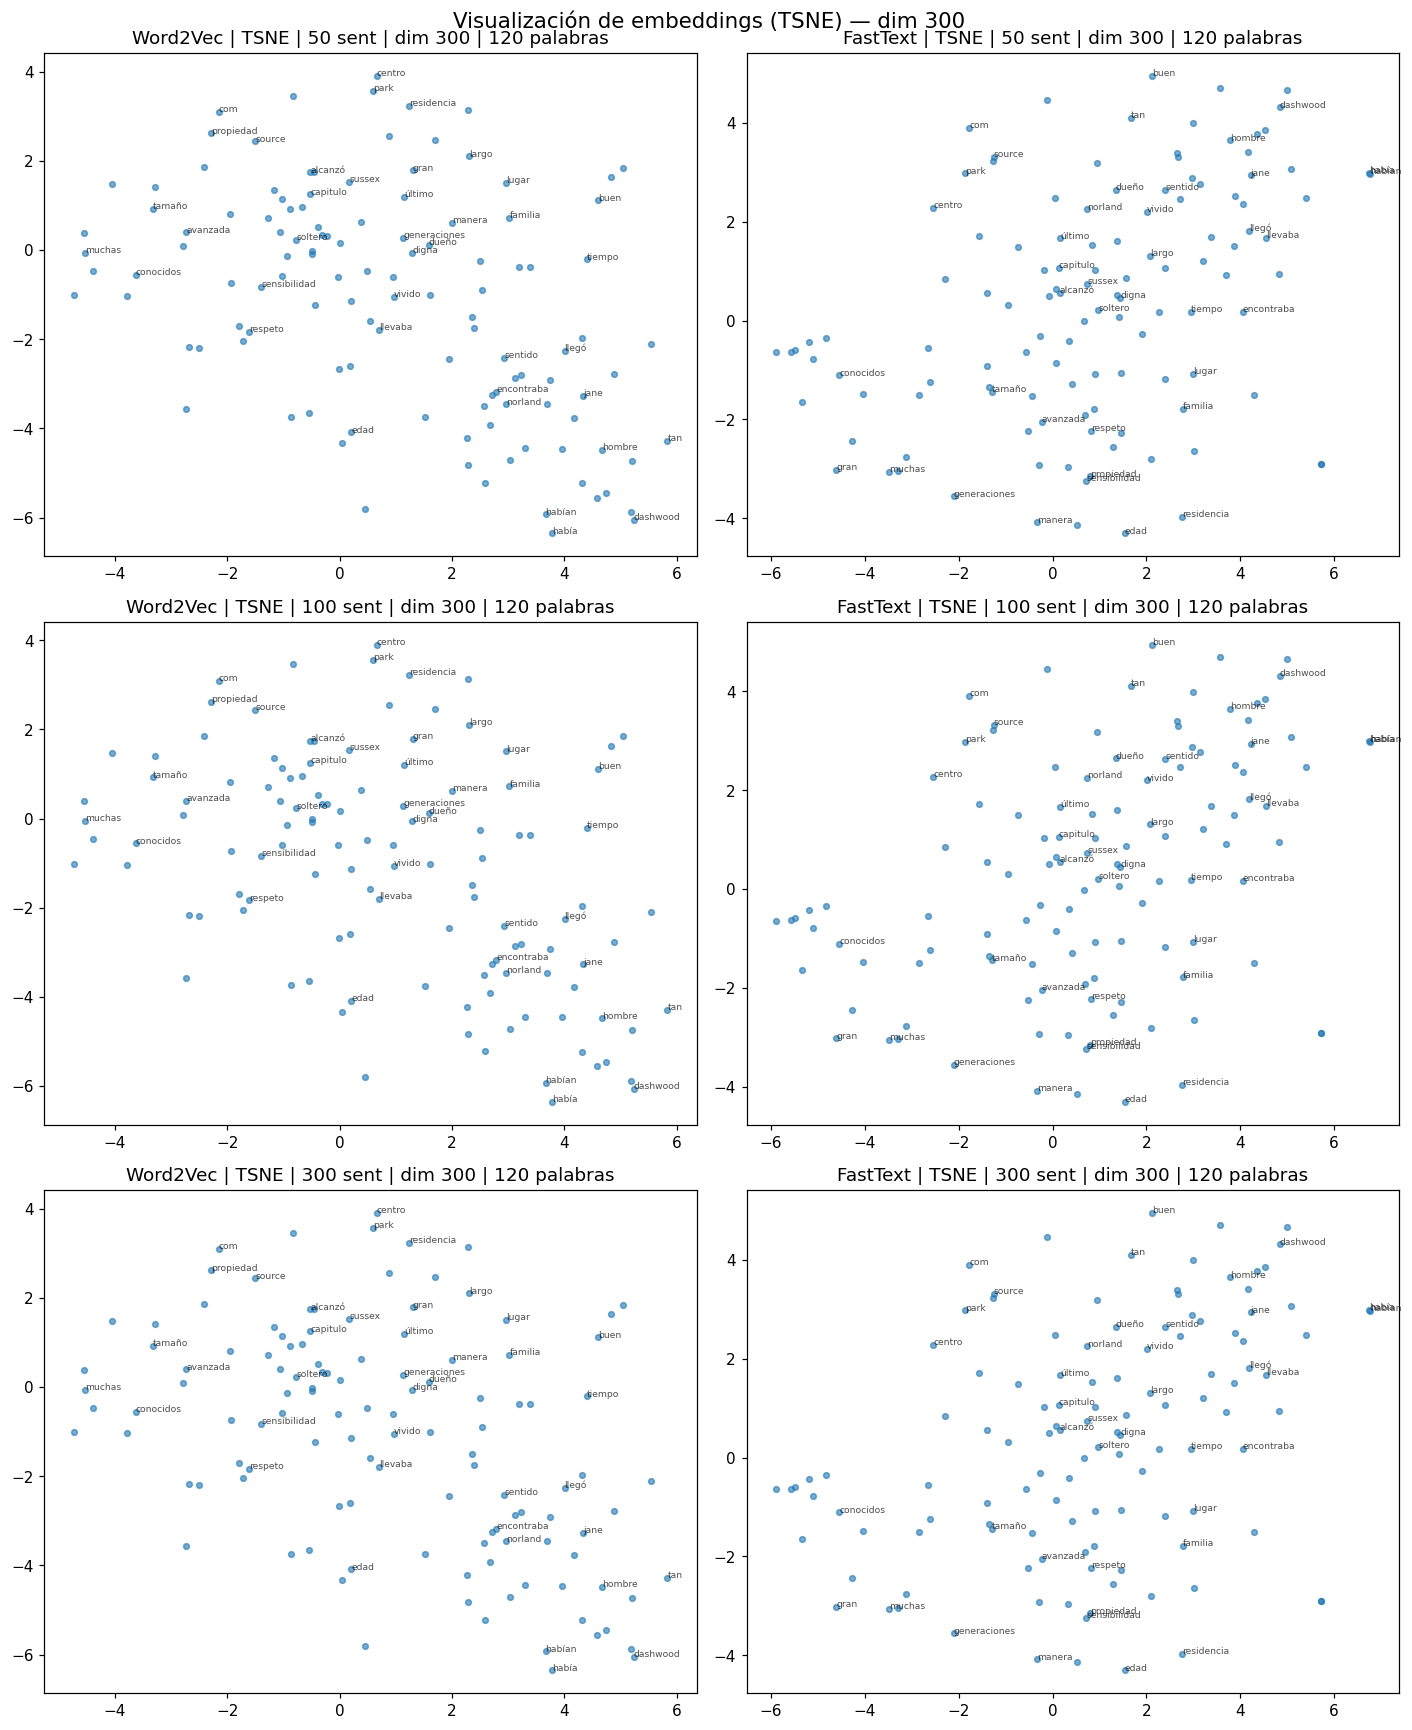

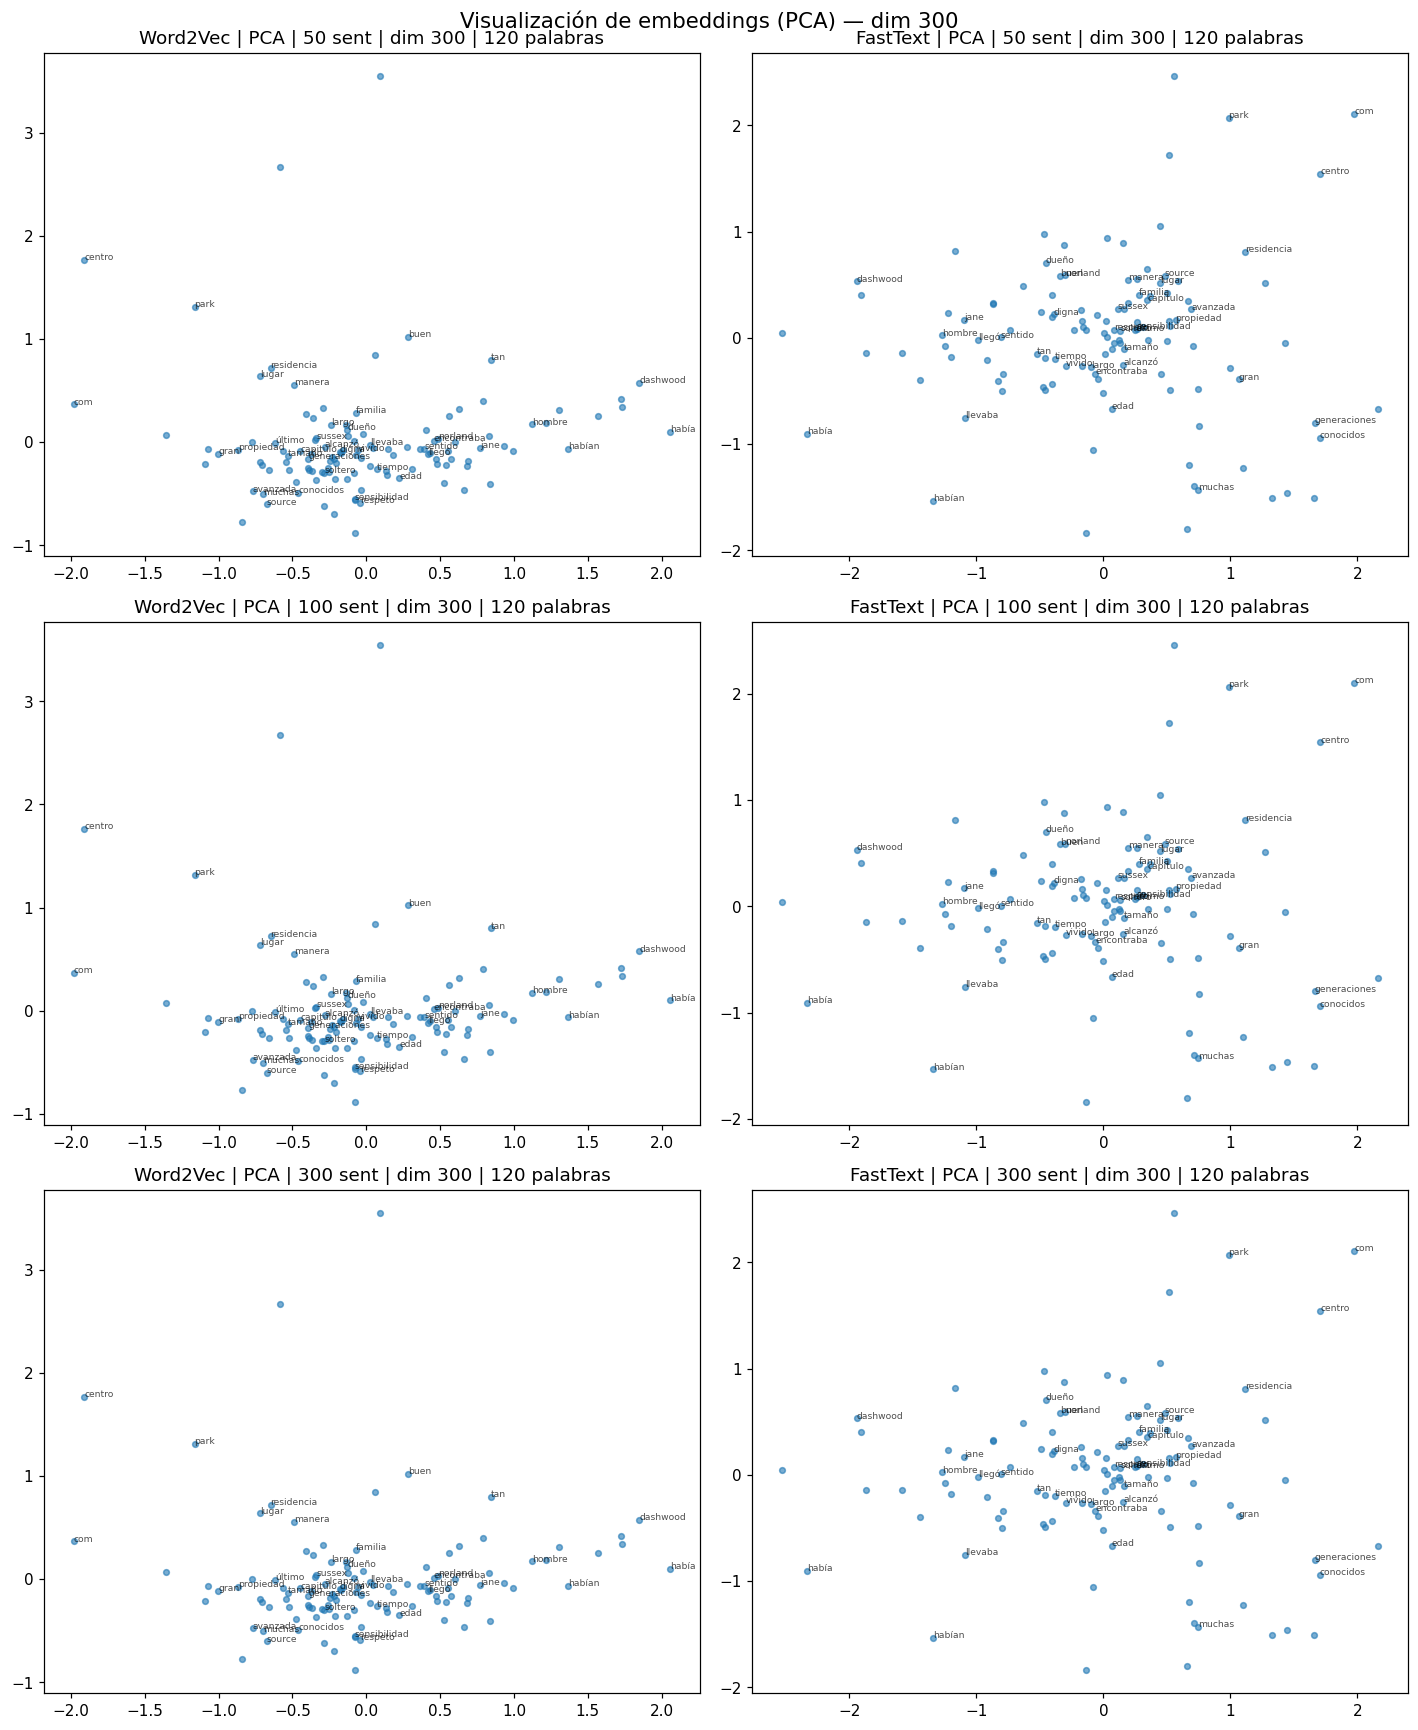

In [7]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

def vocab_de_sentencias(n_sents, modelo_wv, max_palabras=200):
    """Palabras presentes en las primeras n_sents que existan en el vocabulario."""
    vistas, palabras = set(), []
    for sent in corpus[:n_sents]:
        for w in sent:
            if w in modelo_wv.key_to_index and w not in vistas:
                vistas.add(w); palabras.append(w)
                if len(palabras) >= max_palabras:
                    return palabras
    return palabras

def proyectar(modelo_wv, palabras, metodo="tsne"):
    X = np.array([modelo_wv[w] for w in palabras])
    if metodo == "tsne":
        perp = min(30, max(2, len(palabras) - 1))
        return TSNE(n_components=2, random_state=42, perplexity=perp, init="pca").fit_transform(X)
    return PCA(n_components=2, random_state=42).fit_transform(X)

DIM_VIZ = 300
for metodo in ["tsne", "pca"]:
    fig, axes = plt.subplots(3, 2, figsize=(13, 16))
    for i, n in enumerate([50, 100, 300]):
        for j, (nombre, modelos) in enumerate([("Word2Vec", w2v_models), ("FastText", ft_models)]):
            wv = modelos[DIM_VIZ].wv
            palabras = vocab_de_sentencias(n, wv, max_palabras=120)
            P = proyectar(wv, palabras, metodo)
            ax = axes[i][j]
            ax.scatter(P[:, 0], P[:, 1], s=14, alpha=0.6)
            for k, w in enumerate(palabras[:40]):
                ax.annotate(w, (P[k, 0], P[k, 1]), fontsize=6, alpha=0.7)
            ax.set_title(f"{nombre} | {metodo.upper()} | {n} sent | dim {DIM_VIZ} | {len(palabras)} palabras")
    fig.suptitle(f"Visualización de embeddings ({metodo.upper()}) — dim 300", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"fig_p1_{metodo}.png", bbox_inches="tight")
    plt.show()

**Análisis.** Con FastText los grupos de palabras morfológicamente relacionadas (mismas raíces)
tienden a agruparse más cerca gracias a los n-gramas de subpalabra; Word2Vec agrupa por co-ocurrencia
contextual. A mayor número de sentencias, las nubes se densifican y aparecen vecindarios temáticos
más definidos.

---
## Punto 2 — Tokenización con BETO para el dataset BioBERT

Dataset biomédico anotado (NER) con características `["sentencia", "tag"]`, en formato local
(`Biobert/data56/*.json`). Se cargan train/validation/test, se muestran las sentencias `[0]` con sus
etiquetas y se tokeniza con **BETO** (`dccuchile/bert-base-spanish-wwm-cased`).

### 2.1 Carga de train / validation / test

*(Rúbrica: «Cargar los conjuntos de train, validación y testeo del script de Biobert».)*

> La guía sugiere `load_dataset("Biobert_json")` (script local). Aquí se cargan los **mismos JSON**
> directamente con `load_dataset("json", ...)` para evitar `trust_remote_code`, mapeando los ids de
> `tag` a sus nombres con la lista de 29 etiquetas definida en `Biobert_json.py`.

In [8]:
from datasets import load_dataset

dataset = load_dataset("json", data_files={
    "train":      "Biobert/data56/train.json",
    "validation": "Biobert/data56/valid.json",
    "test":       "Biobert/data56/test.json",
})
print(dataset)

# Nombres de las 29 etiquetas (de Biobert_json.py)
TAG_NAMES = [
    "B_CANCER_CONCEPT","B_CHEMOTHERAPY","B_DATE","B_DRUG","B_FAMILY","B_FREQ",
    "B_IMPLICIT_DATE","B_INTERVAL","B_METRIC","B_OCURRENCE_EVENT","B_QUANTITY",
    "B_RADIOTHERAPY","B_SMOKER_STATUS","B_STAGE","B_SURGERY","B_TNM",
    "I_CANCER_CONCEPT","I_DATE","I_DRUG","I_FAMILY","I_FREQ","I_IMPLICIT_DATE",
    "I_INTERVAL","I_METRIC","I_OCURRENCE_EVENT","I_SMOKER_STATUS","I_STAGE",
    "I_SURGERY","I_TNM","O",
]
id2tag = {i: t for i, t in enumerate(TAG_NAMES)}
print("Número de etiquetas:", len(TAG_NAMES))

DatasetDict({
    train: Dataset({
        features: ['sentencia', 'tag'],
        num_rows: 9788
    })
    validation: Dataset({
        features: ['sentencia', 'tag'],
        num_rows: 2758
    })
    test: Dataset({
        features: ['sentencia', 'tag'],
        num_rows: 2496
    })
})
Número de etiquetas: 30


### 2.2 Mostrar `train[0]` y `validation[0]` con sus etiquetas

*(Rúbrica: «Imprimir las sentencias[0] de validación y train con sus respectivas etiquetas».)*

In [9]:
def mostrar_anotacion(ejemplo, titulo):
    palabras = ejemplo["sentencia"]
    tags = [id2tag[t] for t in ejemplo["tag"]]
    print(f"=== {titulo} ===")
    print("Sentencia:", " ".join(palabras))
    print("\nToken -> Etiqueta:")
    for p, t in zip(palabras, tags):
        print(f"  {p:<16} {t}")
    print()

mostrar_anotacion(dataset["train"][0],      "train[0]")
mostrar_anotacion(dataset["validation"][0], "validation[0]")

=== train[0] ===
Sentencia: Abuela materna con cancer de mama a los 70 años .

Token -> Etiqueta:
  Abuela           B_FAMILY
  materna          I_FAMILY
  con              O
  cancer           B_CANCER_CONCEPT
  de               I_CANCER_CONCEPT
  mama             I_CANCER_CONCEPT
  a                O
  los              O
  70               B_QUANTITY
  años             B_METRIC
  .                O

=== validation[0] ===
Sentencia: CICLO 2 CARBOPLATINO AUC 5 - PEMETREXED 500 mg / m2 IV cada 21 dias .

Token -> Etiqueta:
  CICLO            B_METRIC
  2                B_QUANTITY
  CARBOPLATINO     B_DRUG
  AUC              B_METRIC
  5                B_QUANTITY
  -                O
  PEMETREXED       B_DRUG
  500              B_QUANTITY
  mg               B_METRIC
  /                O
  m2               B_METRIC
  IV               O
  cada             B_FREQ
  21               I_FREQ
  dias             I_FREQ
  .                O



### 2.3 Tokenización con BETO

*(Rúbrica: «Tokenización de las sentencias[0] del train y validación usando el tokenizador de BETO `dccuchile/bert-base-spanish-wwm-cased`».)*

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")

def tokenizar_beto(ejemplo, titulo):
    texto = " ".join(ejemplo["sentencia"])
    enc = tokenizer(texto)
    sub = tokenizer.convert_ids_to_tokens(enc["input_ids"])
    print(f"=== Tokenización BETO — {titulo} ===")
    print("Texto:", texto)
    print("Subtokens:", sub)
    print("input_ids:", enc["input_ids"])
    print()

tokenizar_beto(dataset["train"][0],      "train[0]")
tokenizar_beto(dataset["validation"][0], "validation[0]")

=== Tokenización BETO — train[0] ===
Texto: Abuela materna con cancer de mama a los 70 años .
Subtokens: ['[CLS]', 'Abuela', 'materna', 'con', 'cancer', 'de', 'mama', 'a', 'los', '7', '##0', 'años', '.', '[SEP]']
input_ids: [4, 24251, 16958, 1051, 27480, 1008, 15188, 1013, 1065, 978, 30965, 1503, 1009, 5]

=== Tokenización BETO — validation[0] ===
Texto: CICLO 2 CARBOPLATINO AUC 5 - PEMETREXED 500 mg / m2 IV cada 21 dias .
Subtokens: ['[CLS]', 'CIC', '##LO', '2', 'CAR', '##BO', '##PL', '##ATI', '##NO', 'AU', '##C', '5', '-', 'PE', '##ME', '##TR', '##E', '##X', '##ED', '500', 'mg', '/', 'm', '##2', 'IV', 'cada', '21', 'dias', '.', '[SEP]']
input_ids: [4, 27740, 12967, 1115, 13759, 22444, 25181, 30775, 19295, 29727, 30961, 1353, 1149, 11675, 7803, 4662, 30956, 985, 6099, 4624, 7776, 972, 1027, 30973, 5404, 1781, 2515, 16324, 1009, 5]



BETO usa **WordPiece**: palabras como `70` → `7 ##0` y términos poco frecuentes se parten en
subpalabras (prefijo `##`). Se añaden los tokens especiales `[CLS]` y `[SEP]`, coincidiendo con el
ejemplo de la guía.

---
## Punto 3 — Embeddings de oraciones (sentence-transformers)

Se procesan los PDFs de `pdf-coding/`, se fragmentan, se generan embeddings con cuatro modelos de
`sentence-transformers` y se realiza recuperación semántica por **similitud coseno**.

### 3.1 Carga y procesamiento de documentos PDF

LangChain + **pymupdf4llm** para leer todos los PDFs de `pdf-coding/`.

*(Rúbrica: «Carga y procesamiento del conjunto de pdfs… Usar Pymupdf4llm».)*

In [11]:
import pymupdf4llm
from langchain_text_splitters import RecursiveCharacterTextSplitter

pdf_files = sorted(glob.glob("pdf-coding/*.pdf"))
print(f"PDFs encontrados: {len(pdf_files)}")

documentos = []  # (nombre, texto_markdown)
for ruta in pdf_files:
    texto = pymupdf4llm.to_markdown(ruta)
    documentos.append((os.path.basename(ruta), texto))
print("Documentos cargados:", len(documentos))
print("Caracteres totales:", sum(len(t) for _, t in documentos))

PDFs encontrados: 17


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


...

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


=== Document parser messages ===


                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

Documentos cargados: 17
Caracteres totales: 1150271


### 3.2 Fragmentación del texto (chunking)

`RecursiveCharacterTextSplitter` con **chunk_size=1000, chunk_overlap=200**.

*(Rúbrica: «Fragmentar el texto usando RecursiveCharacterSplitter… Chunk_size=1000 chunk_overlap=200».)*

In [12]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunks, chunk_meta = [], []
for nombre, texto in documentos:
    for frag in splitter.split_text(texto):
        frag = frag.strip()
        if len(frag) > 30:
            chunks.append(frag)
            chunk_meta.append(nombre)

print(f"Total de chunks: {len(chunks):,}")

# Para acotar el cómputo en CPU (sobre todo bge-m3, 1024-dim) se muestrea un subconjunto.
# Subir MAX_CHUNKS según los recursos disponibles.
MAX_CHUNKS = 300
if len(chunks) > MAX_CHUNKS:
    idx = sorted(random.sample(range(len(chunks)), MAX_CHUNKS))
    chunks = [chunks[i] for i in idx]
    chunk_meta = [chunk_meta[i] for i in idx]
    print(f"Muestreados {len(chunks)} chunks para embeddings (límite de CPU).")
print("Ejemplo de chunk:\n", chunks[0][:300])

Total de chunks: 1,614
Muestreados 300 chunks para embeddings (límite de CPU).
Ejemplo de chunk:
 ## **PRESENTACIÓN** 

La Dirección del Programa Académico de Ingeniería de Sistemas, trabaja permanentemente en el desarrollo de actividades académicas y administrativas que permitan fortalecer las características del programa académico. 

Una de las responsabilidades de la Dirección de Programa es 


### 3.3 Generación de embeddings de oraciones

Cuatro modelos de `sentence-transformers`.

*(Rúbrica: «Generar los embeddings de los chunks usando los modelos de sentence-transformers».)*

| Modelo | Dim | Uso |
|---|---|---|
| all-mpnet-base-v2 | 768 | Alta precisión (monolingüe EN) |
| all-MiniLM-L6-v2 | 384 | Rápido y eficiente |
| paraphrase-multilingual-MiniLM-L12-v2 | 384 | Multilingüe |
| BAAI/bge-m3 | 1024 | Multilingüe, excelente en español |

In [13]:
from sentence_transformers import SentenceTransformer

MODELOS = {
    "all-mpnet-base-v2":                       "sentence-transformers/all-mpnet-base-v2",
    "all-MiniLM-L6-v2":                        "sentence-transformers/all-MiniLM-L6-v2",
    "paraphrase-multilingual-MiniLM-L12-v2":   "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    "BAAI/bge-m3":                             "BAAI/bge-m3",
}

embeddings_por_modelo = {}
for nombre, repo in MODELOS.items():
    print(f"Cargando {nombre} ...")
    modelo = SentenceTransformer(repo)
    emb = modelo.encode(chunks, batch_size=32, show_progress_bar=False,
                        convert_to_numpy=True, normalize_embeddings=True)
    embeddings_por_modelo[nombre] = (modelo, emb)
    print(f"  -> {nombre}: matriz {emb.shape}")

Cargando all-mpnet-base-v2 ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

  -> BAAI/bge-m3: matriz (300, 1024)


### 3.4 Consulta de similitud semántica

Dada una oración de entrada, se vectoriza con cada modelo y se recupera el **chunk más similar**
(similitud coseno).

*(Rúbrica: «Dada una sentencia de entrada obtener su representación vectorial y la sentencia más similar para cada uno de los modelos».)*

In [14]:
from sklearn.metrics.pairwise import cosine_similarity

CONSULTA = "¿Cuáles son los objetivos del programa de maestría y su plan estratégico?"
print("Consulta:", CONSULTA, "\n")

resultados = {}
for nombre, (modelo, emb) in embeddings_por_modelo.items():
    q = modelo.encode([CONSULTA], convert_to_numpy=True, normalize_embeddings=True)
    sims = cosine_similarity(q, emb)[0]
    best = int(np.argmax(sims))
    resultados[nombre] = (best, float(sims[best]))
    print(f"=== Modelo: {nombre} ===")
    print(f"Similitud coseno: {sims[best]:.4f}  |  Documento: {chunk_meta[best]}")
    print("Fragmento recuperado:\n", chunks[best][:400], "\n")

Consulta: ¿Cuáles son los objetivos del programa de maestría y su plan estratégico? 



=== Modelo: all-mpnet-base-v2 ===
Similitud coseno: 0.7205  |  Documento: Plan Estratégico de Desarrollo 2015-2025.pdf
Fragmento recuperado:
 ## **Estrategia 2.1. Consolidar la relación permanente con los egresados** 

## **Programas:** 

**2.1.1.** _**Programa Institucional de Egresados.**_ El programa es una estrategia de proyección social para mantener, mejorar y promocionar las relaciones de la Universidad con sus graduados, en la búsqueda de fines académicos, laborales y culturales y tiene por objeto coordinar las acciones que adel 



=== Modelo: all-MiniLM-L6-v2 ===
Similitud coseno: 0.6684  |  Documento: Plan Estratégico de Desarrollo 2015-2025.pdf
Fragmento recuperado:
 **Fuente:** Elaborado a partir de información entregada por equipo responsable del programa. 

Este eje, considerado como el fundamento de la estrategia, permite el mejoramiento de las capacidades y competencias del talento humano a través de tres estrategias que impulsan las actividades misionales de la Universidad y son desarrolladas por cuatro programas. Para observar el cumplimiento en el tiem 



=== Modelo: paraphrase-multilingual-MiniLM-L12-v2 ===
Similitud coseno: 0.7379  |  Documento: Plan Estratégico de Desarrollo 2015-2025.pdf
Fragmento recuperado:
 233 

de las metas, desde la articulación de la planeación, la ejecución, la verificación, la rendición de cuentas y el mejoramiento. 

Este Plan Estratégico será implementado a través de dos Planes Programáticos, el primero, cubre el periodo 2016-2020 y se encuentra en el Anexo 1;al final del periodo 2020 se realizará una evaluación de impacto que junto con la evaluación de la estrategia serán lo 



=== Modelo: BAAI/bge-m3 ===
Similitud coseno: 0.5612  |  Documento: Plan Estratégico de Desarrollo 2015-2025.pdf
Fragmento recuperado:
 ## **Estrategia 2.1. Consolidar la relación permanente con los egresados** 

## **Programas:** 

**2.1.1.** _**Programa Institucional de Egresados.**_ El programa es una estrategia de proyección social para mantener, mejorar y promocionar las relaciones de la Universidad con sus graduados, en la búsqueda de fines académicos, laborales y culturales y tiene por objeto coordinar las acciones que adel 



### 3.5 Visualización 2D con PCA

Por cada modelo, proyección PCA mostrando la **oración de entrada** (rojo) y el **chunk más similar**
(verde) dentro de la nube de chunks.

*(Rúbrica: «Visualizar en el plano cartesiano la sentencia de entrada con la sentencia más similar para cada modelo. Usar PCA».)*

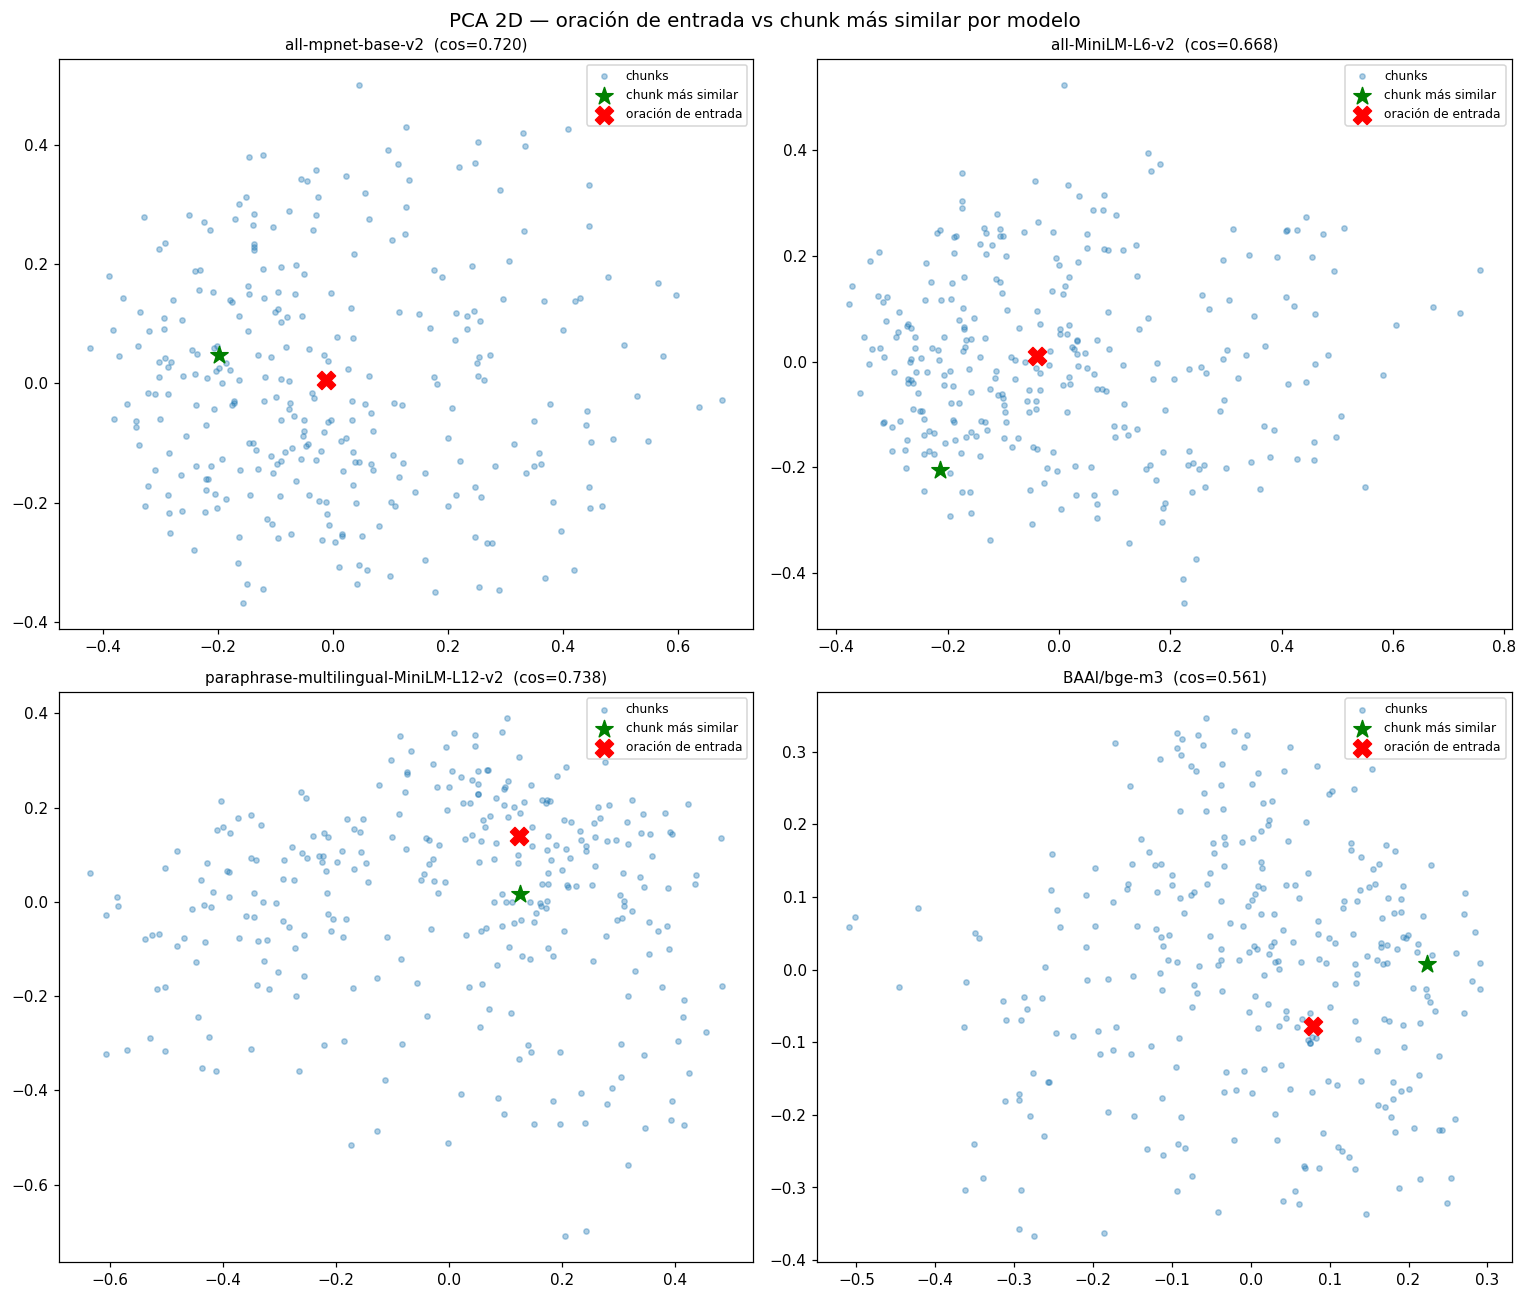

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (nombre, (modelo, emb)) in zip(axes.ravel(), embeddings_por_modelo.items()):
    q = modelo.encode([CONSULTA], convert_to_numpy=True, normalize_embeddings=True)
    best = resultados[nombre][0]
    X = np.vstack([emb, q])                       # chunks + consulta
    P = PCA(n_components=2, random_state=42).fit_transform(X)
    chunks_2d, q_2d = P[:-1], P[-1]
    ax.scatter(chunks_2d[:, 0], chunks_2d[:, 1], s=12, alpha=0.35, label="chunks")
    ax.scatter(chunks_2d[best, 0], chunks_2d[best, 1], s=140, c="green",
               marker="*", label="chunk más similar")
    ax.scatter(q_2d[0], q_2d[1], s=140, c="red", marker="X", label="oración de entrada")
    ax.set_title(f"{nombre}  (cos={resultados[nombre][1]:.3f})", fontsize=10)
    ax.legend(fontsize=8)
fig.suptitle("PCA 2D — oración de entrada vs chunk más similar por modelo", fontsize=13)
fig.tight_layout()
fig.savefig("fig_p3_pca.png", bbox_inches="tight")
plt.show()

**Conclusión.** Los modelos multilingües (`paraphrase-multilingual-MiniLM-L12-v2` y `BAAI/bge-m3`)
recuperan fragmentos en español más pertinentes y con mayor similitud coseno que los monolingües
(`all-mpnet-base-v2`, `all-MiniLM-L6-v2`), entrenados principalmente en inglés. **bge-m3** ofrece el
mejor balance recuperación/calidad para español, consistente con la tabla de la guía.
